# Colonia de Hormigas (ACO) y Fast Ant System

**Serie:** Metaheurísticas desde cero · **Bloque:** 2 – Métodos con memoria · **Notebook 08**

Anterior: [GRASP y Path Relinking](07-grasp-path-relinking.ipynb) · Anterior: [Búsqueda tabú](06-busqueda-tabu.ipynb) ·
Siguiente bloque: [Algoritmos genéticos](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb) ·
Relacionado: [Enjambre y evolución diferencial](../03-metodos-poblacionales/11-enjambre-pso-evolucion-diferencial.ipynb)

## Tabla de contenido
1. Qué vas a aprender y prerrequisitos
2. Intuición: feromona como memoria colectiva
3. Formulación: regla de transición, evaporación, depósito
4. Un "juego de hormigas" a mano (5 ciudades)
5. Utilidades TSP y construcción vectorizada de tours
6. Ant System (AS)
7. Ant Colony System (ACS)
8. MAX-MIN Ant System (MMAS)
9. Fast Ant System (FANT)
10. Comparación con presupuesto igual, sin y con búsqueda local
11. Efecto de $\alpha$, $\beta$ y $\rho$
12. Visualización de la matriz de feromona y factor de ramificación
13. Ventajas y limitaciones, resumen, ejercicios, referencias

## 1. Qué vas a aprender y prerrequisitos

**Objetivo.** Entender la optimización por colonias de hormigas (ACO, *Ant Colony Optimization*) como un método **constructivo con
memoria**: la memoria es una matriz de **feromona** que se actualiza con la experiencia colectiva y sesga las construcciones futuras.
Implementamos cuatro variantes desde cero para el TSP: **AS**, **ACS**, **MMAS** y **FANT**.

**Al terminar sabrás:**
- calcular la regla probabilística de transición y verificar que la implementación vectorizada la respeta;
- explicar el papel de la evaporación, el depósito y los **límites de feromona** (derivados, no solo enunciados);
- distinguir AS, ACS, MMAS y FANT (cuántas hormigas depositan, quién se refuerza, cómo se evita el estancamiento);
- medir el efecto de $\alpha$, $\beta$, $\rho$ con varias semillas y reportar media $\pm$ desviación;
- visualizar la matriz de feromona y el **factor de ramificación** como diagnóstico de convergencia.

**Prerrequisitos.** TSP y heurísticas constructivas ([notebook 02](../01-metodos-de-trayectoria/02-metodos-constructivos.ipynb)),
búsqueda local 2-opt, nociones de probabilidad.

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng_global = np.random.default_rng(2024)

## 2. Intuición

Las hormigas reales depositan feromona al caminar; las trayectorias más cortas se recorren más veces por unidad de tiempo y acumulan
más feromona, y la evaporación borra los rastros viejos. Ese bucle de retroalimentación positiva (**estigmergia**: comunicación a
través del ambiente) hace emerger caminos cortos sin que ninguna hormiga conozca el problema completo (Dorigo, Maniezzo & Colorni, 1996).

> **Analogía.** Un grupo de excursionistas deja marcas de tiza en las bifurcaciones. Quienes llegan antes a la meta repiten el
> camino varias veces (más marcas); la lluvia (evaporación) borra marcas viejas. Al cabo de un tiempo, el camino más marcado es
> el más corto, pero hay que dejar que algunos excursionistas exploren: si todos siguen la marca más gruesa, se estancan en el
> primer camino decente.

Mapeo a optimización: cada **hormiga** construye una solución completa (un tour) eligiendo ciudades una a una; la **feromona**
$\tau_{ij}$ acumula la "deseabilidad" aprendida de la arista $(i,j)$; la **heurística** $\eta_{ij}=1/d_{ij}$ es información
local estática (voracidad). Es un método **constructivo con memoria adaptativa**, a diferencia de GRASP, que construye sin memoria
(ver [notebook 07](07-grasp-path-relinking.ipynb)).

## 3. Formulación

**Regla de transición (Ant System).** La hormiga $k$ en la ciudad $i$, con conjunto de ciudades no visitadas $\mathcal{N}_i^k$, elige $j$ con probabilidad

$$
p_{ij}^k=\frac{[\tau_{ij}]^{\alpha}\,[\eta_{ij}]^{\beta}}{\sum_{l\in\mathcal{N}_i^k}[\tau_{il}]^{\alpha}\,[\eta_{il}]^{\beta}},\qquad j\in\mathcal{N}_i^k .
$$

$\alpha$ pondera la **experiencia colectiva** y $\beta$ la **voracidad local**: $\alpha=0$ reduce el método a una construcción golosa
estocástica; $\beta=0$ usa solo feromona (convergencia rápida y a menudo prematura).

**Evaporación y depósito.** Tras cada iteración, con $\rho\in(0,1]$ la tasa de evaporación:

$$
\tau_{ij}\leftarrow(1-\rho)\,\tau_{ij}+\sum_{k=1}^{m}\Delta\tau_{ij}^{k},\qquad
\Delta\tau_{ij}^{k}=\begin{cases}Q/L_k & \text{si la hormiga } k \text{ usó } (i,j)\\ 0&\text{en otro caso}\end{cases}
$$

**Dinámica de la feromona.** Sin depósitos, $\tau_{ij}(t)=(1-\rho)^t\tau_{ij}(0)$: vida media $t_{1/2}=\ln 2/(-\ln(1-\rho))\approx 0.69/\rho$.
Si una arista recibe un depósito constante $\Delta$ en cada iteración, la recurrencia $\tau_{t+1}=(1-\rho)\tau_t+\Delta$ converge a
$$\tau^{*}=\frac{\Delta}{\rho}.$$
Con $\Delta=1/L^{*}$ (depósito de la mejor solución, $Q=1$) se obtiene el **techo natural** $\tau_{\max}=1/(\rho L^{*})$, que MMAS impone explícitamente. Lo verificamos numéricamente más abajo.

**Variantes.**

| | AS | ACS | MMAS | FANT |
|---|---|---|---|---|
| Hormigas | $m$ | $m$ | $m$ | **1** por iteración |
| Quién deposita | todas, $\propto1/L_k$ | solo la mejor global (actualización global) | solo una (mejor de la iteración o global) | la actual ($r$) y la mejor ($R$) |
| Regla de elección | proporcional | pseudo-aleatoria proporcional con $q_0$ | proporcional | proporcional a $\tau$ (sin $\eta$) |
| Control del estancamiento | evaporación | actualización local $\tau\leftarrow(1-\xi)\tau+\xi\tau_0$ | límites $[\tau_{\min},\tau_{\max}]$ + reinicio | reinicio de la traza y aumento de $r$ |

## 4. Un "juego de hormigas" a mano

Antes de implementar, simulemos a mano **una iteración** con 5 ciudades y 3 hormigas. Muestra exactamente qué hace cada fórmula.
Distancias enteras pequeñas (matriz simétrica), $\alpha=1$, $\beta=2$, $\rho=0.5$, $Q=10$, $\tau_0=1$.

In [2]:
# Mini-instancia de 5 ciudades (distancias a mano)
Dm = np.array([[0, 2, 9, 10, 7],
               [2, 0, 6, 4, 3],
               [9, 6, 0, 8, 5],
               [10, 4, 8, 0, 6],
               [7, 3, 5, 6, 0]], float)
n_m = 5; al, be, rho_m, Q_m = 1.0, 2.0, 0.5, 10.0
eta_m = np.where(Dm > 0, 1.0 / np.where(Dm > 0, Dm, 1), 0.0)
tau_m = np.ones((n_m, n_m)) - np.eye(n_m)

# Probabilidades desde la ciudad 0 con todas las demás sin visitar
w = (tau_m[0] ** al) * (eta_m[0] ** be); w[0] = 0
p0 = w / w.sum()
print("Probabilidades de la ciudad 0 → j:", np.round(p0, 4), "(suma =", round(p0.sum(), 6), ")")

# Verificación empírica del muestreo (la misma forma de muestrear que usaremos vectorizada)
rg = np.random.default_rng(0)
c = p0.cumsum(); muestras = (c[None, :] < rg.random((200000, 1))).sum(1)
print("Frecuencias empíricas (200 000 muestras):", np.round(np.bincount(muestras, minlength=5) / 200000, 4))

# Tres hormigas parten de las ciudades 0, 1, 2: construimos sus tours con la regla
def tour_hormiga(inicio, rg):
    vis = {inicio}; t = [inicio]
    while len(t) < n_m:
        i = t[-1]; cand = [j for j in range(n_m) if j not in vis]
        pw = np.array([(tau_m[i, j] ** al) * (eta_m[i, j] ** be) for j in cand]); pw /= pw.sum()
        j = int(rg.choice(cand, p=pw)); t.append(j); vis.add(j)
    return t
rg = np.random.default_rng(4)
tours_m = [tour_hormiga(s, rg) for s in (0, 1, 2)]
Ls_m = [sum(Dm[t[i], t[(i + 1) % n_m]] for i in range(n_m)) for t in tours_m]
for t, L in zip(tours_m, Ls_m):
    print(f"tour {t}  largo = {L:.0f}  depósito por arista = Q/L = {Q_m / L:.3f}")

# Evaporación y depósito
tau_new = (1 - rho_m) * tau_m
for t, L in zip(tours_m, Ls_m):
    for i in range(n_m):
        a, b = t[i], t[(i + 1) % n_m]
        tau_new[a, b] += Q_m / L; tau_new[b, a] += Q_m / L
np.fill_diagonal(tau_new, 0)
print("\nFeromona tras evaporar (×0.5) y depositar:\n", np.round(tau_new, 3))
mejor_t = tours_m[int(np.argmin(Ls_m))]
print("Mejor tour de la iteración:", mejor_t, "; sus aristas tienen ahora más feromona que 0.5 (el piso evaporado).")

Probabilidades de la ciudad 0 → j: [0.     0.854  0.0422 0.0342 0.0697] (suma = 1.0 )
Frecuencias empíricas (200 000 muestras): [0.     0.8553 0.0423 0.0337 0.0687]
tour [0, 4, 1, 3, 2]  largo = 31  depósito por arista = Q/L = 0.323
tour [1, 2, 3, 4, 0]  largo = 29  depósito por arista = Q/L = 0.345
tour [2, 4, 1, 3, 0]  largo = 31  depósito por arista = Q/L = 0.323

Feromona tras evaporar (×0.5) y depositar:
 [[0.    0.845 1.145 0.823 1.167]
 [0.845 0.    0.845 1.145 1.145]
 [1.145 0.845 0.    1.167 0.823]
 [0.823 1.145 1.167 0.    0.845]
 [1.167 1.145 0.823 0.845 0.   ]]
Mejor tour de la iteración: [1, 2, 3, 4, 0] ; sus aristas tienen ahora más feromona que 0.5 (el piso evaporado).


## 5. Utilidades y construcción vectorizada

Todas las hormigas de una iteración se mueven **en paralelo** (matrices $m\times n$): en cada paso se calculan los pesos
$\tau^\alpha\eta^\beta$ de la fila de la ciudad actual de cada hormiga, se enmascaran las visitadas y se muestrea con la
suma acumulada. Verificaremos que cada fila resultante sea una permutación válida.

In [3]:
def crear_tsp(n, rng):
    P = rng.random((n, 2))
    D = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1))
    return P, D

def largos(D, tours):
    # Largo de cada tour (filas de 'tours'), vectorizado.
    return D[tours, np.roll(tours, -1, axis=1)].sum(1)

def es_permutacion_filas(tours):
    n = tours.shape[1]
    return bool((np.sort(tours, axis=1) == np.arange(n)[None, :]).all())

def vecino_mas_cercano(D, inicio=0):
    n = len(D); vis = np.zeros(n, bool); cur = inicio; t = [cur]; vis[cur] = True
    for _ in range(n - 1):
        c = np.where(vis, np.inf, D[cur]); cur = int(np.argmin(c)); t.append(cur); vis[cur] = True
    return np.array(t)

def construir_hormigas(tau, eta, alpha, beta, m, rng, q0=0.0, xi=0.0, tau0=0.0, local=False):
    # Construye m tours en paralelo. q0>0: regla pseudo-aleatoria proporcional de ACS.
    # local=True: actualización local de ACS tau <- (1-xi) tau + xi tau0 tras cada paso.
    n = len(tau)
    tours = np.empty((m, n), dtype=np.int64); vis = np.zeros((m, n), bool)
    cur = rng.integers(n, size=m); tours[:, 0] = cur; vis[np.arange(m), cur] = True
    for k in range(1, n):
        w = np.where(vis, 0.0, (tau[cur] ** alpha) * (eta[cur] ** beta))
        c = w.cumsum(1); r = rng.random(m) * c[:, -1]
        nxt = np.minimum((c < r[:, None]).sum(1), n - 1)                 # muestreo proporcional
        if q0 > 0:                                                       # explotación determinista con prob. q0
            nxt = np.where(rng.random(m) < q0, w.argmax(1), nxt)
        if local:
            for j in range(m):
                a, b = cur[j], nxt[j]
                tau[a, b] = tau[b, a] = (1 - xi) * tau[a, b] + xi * tau0
        tours[:, k] = nxt; vis[np.arange(m), nxt] = True; cur = nxt
    return tours

def depositar(tau, tour, cantidad):
    a = tour; b = np.roll(tour, -1)
    tau[a, b] += cantidad; tau[b, a] += cantidad

# Instancia y verificaciones
N = 50
P, D = crear_tsp(N, np.random.default_rng(12))
eta = 1.0 / (D + np.eye(N))            # diagonal sin uso (se enmascara)
L_nn = min(largos(D, vecino_mas_cercano(D, s)[None, :])[0] for s in range(N))
tau_t = np.ones((N, N))
T = construir_hormigas(tau_t, eta, 1.0, 2.0, 200, np.random.default_rng(0))
print("Todos los tours son permutaciones válidas:", es_permutacion_filas(T))
print(f"Instancia n={N}. Mejor vecino más cercano (50 inicios): {L_nn:.3f}; largo medio de las hormigas (τ uniforme, β=2): {largos(D, T).mean():.3f}")

# Verificación de la regla de transición: frecuencia del primer paso desde la ciudad 0 vs. fórmula
tau_u = np.ones((N, N)); m_big = 40000
Tbig = construir_hormigas(tau_u, eta, 1.0, 2.0, m_big, np.random.default_rng(1))
sel = Tbig[Tbig[:, 0] == 0]
teo = (eta[0] ** 2); teo[0] = 0; teo /= teo.sum()
emp = np.bincount(sel[:, 1], minlength=N) / len(sel)
print(f"Primer paso desde la ciudad 0 ({len(sel)} hormigas): error máximo |frec. empírica - p_ij teórica| = {np.abs(emp - teo).max():.4f}")

Todos los tours son permutaciones válidas: True
Instancia n=50. Mejor vecino más cercano (50 inicios): 6.946; largo medio de las hormigas (τ uniforme, β=2): 13.169


Primer paso desde la ciudad 0 (753 hormigas): error máximo |frec. empírica - p_ij teórica| = 0.0309


**Verificación del techo de feromona.** Si una sola arista recibe un depósito constante $\Delta=1/L^{*}$ cada iteración, su feromona converge a $\tau^{*}=\Delta/\rho=1/(\rho L^{*})$:

In [4]:
Lstar = 6.0
for rho_ in (0.02, 0.1, 0.5):
    tau_e = 0.0
    for _ in range(int(20 / rho_)):
        tau_e = (1 - rho_) * tau_e + 1.0 / Lstar
    print(f"ρ={rho_:<4}: τ tras iterar = {tau_e:.5f}   | 1/(ρ L*) = {1/(rho_*Lstar):.5f}   | vida media = {np.log(2)/(-np.log(1-rho_)):.1f} iteraciones")

ρ=0.02: τ tras iterar = 8.33333   | 1/(ρ L*) = 8.33333   | vida media = 34.3 iteraciones
ρ=0.1 : τ tras iterar = 1.66667   | 1/(ρ L*) = 1.66667   | vida media = 6.6 iteraciones
ρ=0.5 : τ tras iterar = 0.33333   | 1/(ρ L*) = 0.33333   | vida media = 1.0 iteraciones


## 6. Ant System (AS)

La versión original (Dorigo, Maniezzo & Colorni, 1996): las $m$ hormigas depositan $Q/L_k$ en sus aristas. Inicialización
$\tau_0=m/L_{nn}$ ($L_{nn}$: largo del tour de vecino más cercano). Cada función devuelve el historial del mejor global y diagnósticos:
instantáneas de la feromona y el **factor de ramificación** $\lambda$ (se define en la sección 12).

In [5]:
def factor_ramificacion(tau, lam=0.05):
    # Nº medio de aristas por nodo con feromona > tmin_i + lam (tmax_i - tmin_i) (Gambardella & Dorigo).
    n = len(tau); M = tau + np.where(np.eye(n, dtype=bool), np.nan, 0)
    tmin = np.nanmin(M, 1); tmax = np.nanmax(M, 1)
    umbral = tmin + lam * (tmax - tmin)
    return float(((M > umbral[:, None]) & ~np.eye(n, dtype=bool)).sum(1).mean())

def busqueda_local_2opt(D, t, I, J):
    t = t.copy(); L = D[t, np.roll(t, -1)].sum()
    while True:
        a = t; b = np.roll(t, -1)
        d = D[a[I], a[J]] + D[b[I], b[J]] - D[a[I], b[I]] - D[a[J], b[J]]
        k = int(np.argmin(d))
        if d[k] >= -1e-12:
            return t, L
        t = t.copy(); t[I[k] + 1:J[k] + 1] = t[I[k] + 1:J[k] + 1][::-1]; L += d[k]

def pares_2opt(n):
    I, J = np.triu_indices(n, 2); m = ~((I == 0) & (J == n - 1)); return I[m], J[m]
_PARES = {}
def pares_cache(n):
    if n not in _PARES: _PARES[n] = pares_2opt(n)
    return _PARES[n]

def mejorar_ls(D, tours):
    out = np.empty_like(tours); I_, J_ = pares_cache(len(D))
    for k in range(len(tours)):
        out[k], _ = busqueda_local_2opt(D, tours[k], I_, J_)
    return out

def aco(D, variante, iters, m, rng, alpha=1.0, beta=2.0, rho=0.1, ls=False, q0=0.9, xi=0.1,
        pb=0.05, lam_tmax_cada=5, snaps=(), Q=1.0):
    # Ant System ('as'), Ant Colony System ('acs') o MAX-MIN Ant System ('mmas').
    n = len(D); eta = 1.0 / (D + np.eye(n)); Lnn = largos(D, vecino_mas_cercano(D, 0)[None, :])[0]
    if variante == "as":
        tau = np.full((n, n), m / Lnn); tau0 = tau[0, 1]
    elif variante == "acs":
        tau0 = 1.0 / (n * Lnn); tau = np.full((n, n), tau0)
    else:                                                    # mmas
        tmax = 1.0 / (rho * Lnn); pbn = pb ** (1.0 / n); tmin = tmax * (1 - pbn) / ((n / 2 - 1) * pbn)
        tau = np.full((n, n), tmax)
    mejor, t_mejor = np.inf, None; h_mej, h_it, h_ram = [], [], []; instant = {}; sin_mejora = 0
    for it in range(iters):
        if variante == "acs":
            T = construir_hormigas(tau, eta, alpha, beta, m, rng, q0=q0, xi=xi, tau0=tau0, local=True)
        else:
            T = construir_hormigas(tau, eta, alpha, beta, m, rng)
        if ls:
            T = mejorar_ls(D, T)
        assert es_permutacion_filas(T)
        L = largos(D, T); k = int(np.argmin(L))
        if L[k] < mejor - 1e-12:
            mejor, t_mejor, sin_mejora = L[k], T[k].copy(), 0
            if variante == "mmas":
                tmax = 1.0 / (rho * mejor); tmin = tmax * (1 - pbn) / ((n / 2 - 1) * pbn)
        else:
            sin_mejora += 1
        # --- actualización de feromona ---
        if variante == "as":
            tau *= (1 - rho)
            for j in range(m):
                depositar(tau, T[j], Q / L[j])
        elif variante == "acs":                              # global: solo aristas de la mejor global
            a = t_mejor; b = np.roll(t_mejor, -1)
            tau[a, b] = (1 - rho) * tau[a, b] + rho / mejor; tau[b, a] = tau[a, b]
        else:                                                # mmas
            tau *= (1 - rho)
            if (it + 1) % lam_tmax_cada == 0:
                depositar(tau, t_mejor, 1.0 / mejor)         # cada 5 iteraciones deposita la mejor global
            else:
                depositar(tau, T[k], 1.0 / L[k])             # el resto, la mejor de la iteración
            np.clip(tau, tmin, tmax, out=tau)
            if sin_mejora >= max(30, iters // 4):            # reinicio por estancamiento
                tau[:] = tmax; sin_mejora = 0
        h_mej.append(mejor); h_it.append(L.min()); h_ram.append(factor_ramificacion(tau))
        if it in snaps:
            instant[it] = tau.copy()
    assert es_permutacion_filas(t_mejor[None, :]) and abs(largos(D, t_mejor[None, :])[0] - mejor) < 1e-9
    return dict(mejor=mejor, tour=t_mejor, hist=np.array(h_mej), hist_it=np.array(h_it), ramif=np.array(h_ram),
                snaps=instant, tau=tau, tours_construidos=(np.arange(iters) + 1) * m)

t0 = time.time()
r_as = aco(D, "as", 100, 20, np.random.default_rng(0), alpha=1, beta=2, rho=0.5)
print(f"AS (m=20, 100 iteraciones, ρ=0.5): mejor = {r_as['mejor']:.4f}  [{time.time()-t0:.1f}s]  (vecino más cercano: {L_nn:.4f})")

AS (m=20, 100 iteraciones, ρ=0.5): mejor = 5.6498  [0.1s]  (vecino más cercano: 6.9461)


## 7. Ant Colony System (ACS)

ACS (Dorigo & Gambardella, 1997) introduce tres cambios para **intensificar sin estancarse**:

1. **Regla pseudo-aleatoria proporcional.** Con probabilidad $q_0$ la hormiga **explota**: elige $\arg\max_j\tau_{ij}\eta_{ij}^\beta$;
   con probabilidad $1-q_0$ explora con la regla proporcional de AS.
2. **Actualización global:** solo la mejor hormiga **global** deposita: $\tau_{ij}\leftarrow(1-\rho)\tau_{ij}+\rho/L_{bs}$ sobre sus aristas (la evaporación solo afecta a esas aristas).
3. **Actualización local:** al cruzar una arista, $\tau_{ij}\leftarrow(1-\xi)\tau_{ij}+\xi\tau_0$. Esto **disminuye** la feromona de las aristas
   recién usadas y empuja a las siguientes hormigas hacia caminos diferentes (diversificación). Con $\tau_0=1/(nL_{nn})$.

La actualización local se aplica durante la construcción; en nuestra implementación las $m$ hormigas avanzan en paralelo un paso y
actualizan una tras otra dentro de cada paso (aproximación estándar de ACS paralelo).

## 8. MAX-MIN Ant System (MMAS)

MMAS (Stützle & Hoos, 2000) ataca el estancamiento de AS con cuatro cambios:
1. **Solo una hormiga deposita** (la mejor de la iteración o la mejor global, alternando) → intensificación controlada.
2. **Límites de feromona** $[\tau_{\min},\tau_{\max}]$ con $\tau_{\max}=1/(\rho L^*)$ (el punto fijo que derivamos en la sección 3) y
   $\tau_{\min}=\tau_{\max}\,\dfrac{1-\sqrt[n]{p_{\text{best}}}}{(n/2-1)\sqrt[n]{p_{\text{best}}}}$: garantiza que toda arista conserve una probabilidad mínima
   de ser elegida; $p_{\text{best}}$ es la probabilidad de que la hormiga reconstruya el mejor tour cuando la feromona está en su estado convergido.
3. **Inicialización en $\tau_{\max}$**: exploración fuerte al principio.
4. **Reinicio** de la feromona a $\tau_{\max}$ al detectar estancamiento (aquí: sin mejorar el mejor global en $\max(30,\text{iters}/4)$ iteraciones).

In [6]:
t0 = time.time()
r_acs = aco(D, "acs", 100, 20, np.random.default_rng(0), alpha=1, beta=2, rho=0.1, q0=0.9, xi=0.1)
r_mm = aco(D, "mmas", 100, 20, np.random.default_rng(0), alpha=1, beta=2, rho=0.1)
print(f"ACS: {r_acs['mejor']:.4f} | MMAS: {r_mm['mejor']:.4f} | AS: {r_as['mejor']:.4f}   [{time.time()-t0:.1f}s]")

# Verificación de los límites de MMAS: tras la corrida la feromona debe estar dentro de [tmin, tmax]
n_ = N; rho_ = 0.1; tmax_ = 1 / (rho_ * r_mm["mejor"]); pbn = 0.05 ** (1 / n_)
tmin_ = tmax_ * (1 - pbn) / ((n_ / 2 - 1) * pbn)
tt = r_mm["tau"][~np.eye(N, dtype=bool)]
print(f"MMAS: τ_min={tmin_:.5f}, τ_max={tmax_:.5f} (τ_max/τ_min = {tmax_/tmin_:.1f}); rango observado de τ: [{tt.min():.5f}, {tt.max():.5f}]")
assert tt.min() >= tmin_ - 1e-9 and tt.max() <= tmax_ + 1e-9, "la feromona salió de [tmin, tmax]"

ACS: 5.5195 | MMAS: 5.5348 | AS: 5.6498   [0.2s]
MMAS: τ_min=0.00465, τ_max=1.80676 (τ_max/τ_min = 388.7); rango observado de τ: [0.00465, 1.80425]


## 9. Fast Ant System (FANT)

FANT (Taillard, 1998) simplifica ACO radicalmente para eliminar parámetros: **una sola hormiga** por iteración, **sin evaporación
ni información heurística**, y solo dos parámetros: la **intensificación** $R$ (peso de la mejor solución) y la **exploración** $r$
(peso de la solución actual, variable). Es un método de **memoria como traza**:

```
FANT(R, iteraciones):
    r ← 1;  τ_ij ← r para todo i≠j;  mejor ← ∞
    repetir:
        s ← construir tour con P(j | i) ∝ τ_ij  (entre no visitadas)
        s ← búsqueda local(s)
        si f(s) < f(mejor):                  # nuevo mejor → intensificación fresca
            mejor ← s;  r ← 1;  τ_ij ← r                      (se reinicia la traza)
        si no, si s = mejor:                 # estancamiento: la hormiga reconstruye el mejor
            r ← r + 1;  τ_ij ← r                              (DIVERSIFICACIÓN: se diluye la memoria)
        si no:
            τ_ij += r  para las aristas de s                  (refuerzo de la solución actual)
            τ_ij += R  para las aristas de mejor              (intensificación hacia la mejor)
```

La memoria se "olvida" no por evaporación sino por **reinicio**. Al estancarse, $r$ aumenta: la traza uniforme vale $r$ pero el
refuerzo de la mejor sigue siendo $R$ (fijo), de modo que el peso **relativo** de la mejor solución ($R/r$) decrece y las
construcciones se vuelven más exploratorias. Hay un único parámetro de problema ($R$).

In [7]:
def construir_fant(tau, rng):
    # Una hormiga: elige cada siguiente ciudad proporcional a tau (sin heurística).
    n = len(tau); vis = np.zeros(n, bool); cur = int(rng.integers(n)); t = [cur]; vis[cur] = True
    for _ in range(n - 1):
        w = np.where(vis, 0.0, tau[cur]); c = w.cumsum()
        j = min(int((c < rng.random() * c[-1]).sum()), n - 1)
        t.append(j); vis[j] = True; cur = j
    return np.array(t)

def clave_tour(t):
    p = int(np.where(t == 0)[0][0]); r = np.roll(t, -p)
    if r[1] > r[-1]: r = np.concatenate(([0], r[1:][::-1]))
    return r.tobytes()

def fant(D, n_tours, rng, R=1, ls=True):
    n = len(D); r = 1; tau = np.full((n, n), float(r)); np.fill_diagonal(tau, 0); I_, J_ = pares_cache(n)
    mejor, t_mejor, k_mejor = np.inf, None, None; hist = []; reinicios = 0; est = 0
    for it in range(n_tours):
        t = construir_fant(tau, rng)
        if ls:
            t, L = busqueda_local_2opt(D, t, I_, J_)
        else:
            L = largos(D, t[None, :])[0]
        if L < mejor - 1e-12:
            mejor, t_mejor, k_mejor = L, t.copy(), clave_tour(t); r = 1
            tau[:] = r; np.fill_diagonal(tau, 0); reinicios += 1
        elif clave_tour(t) == k_mejor:
            r += 1; tau[:] = r; np.fill_diagonal(tau, 0); est += 1
        else:
            depositar(tau, t, r); depositar(tau, t_mejor, R)
        hist.append(mejor)
    assert es_permutacion_filas(t_mejor[None, :]) and abs(largos(D, t_mejor[None, :])[0] - mejor) < 1e-9
    return dict(mejor=mejor, tour=t_mejor, hist=np.array(hist), est=est, tau=tau, reinicios=reinicios)

t0 = time.time()
r_f = fant(D, 300, np.random.default_rng(0), R=1, ls=True)
print(f"FANT + 2-opt (300 iteraciones): mejor = {r_f['mejor']:.4f}; mejoras del récord = {r_f['reinicios']}; veces que reconstruyó el mejor = {r_f['est']}  [{time.time()-t0:.1f}s]")

FANT + 2-opt (300 iteraciones): mejor = 5.5195; mejoras del récord = 7; veces que reconstruyó el mejor = 7  [0.4s]


## 10. Comparación con presupuesto igual

Contamos el **número de tours construidos** como unidad de presupuesto. Dos escenarios, 8 semillas cada uno (mismas semillas para
todos los algoritmos): (A) **sin búsqueda local**, $n=50$, 2000 tours; (B) **con 2-opt** aplicado a cada tour construido, $n=100$, 300 tours.
FANT usa una hormiga por iteración (2000 y 300 iteraciones). Parámetros típicos de la literatura (AS: $\rho=0.5$; ACS: $\rho=0.1$, $q_0=0.9$, $\xi=0.1$;
MMAS: $\rho=0.1$; $\alpha=1$, $\beta=2$ para todos; FANT: $R=1$), sin ajuste fino por algoritmo. El escenario B usa una instancia **más grande** ($n=100$): en $n=50$ el 2-opt
dentro de ACO ya encuentra siempre el mismo tour (probable óptimo) y no se distinguen los algoritmos.

In [8]:
SEM = list(range(8))
def resumen(x):
    x = np.asarray(x); return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}"

M_ANTS = 20; IT_A = 100                     # escenario A: 2000 tours
M_B = 10; IT_B = 30                         # escenario B: 300 tours
P100, D100 = crear_tsp(100, np.random.default_rng(13))
L_nn100 = min(largos(D100, vecino_mas_cercano(D100, s)[None, :])[0] for s in range(100))
t0 = time.time()
resA, resB = {}, {}
for nombre, var, kw in [("AS (ρ=0.5)", "as", dict(rho=0.5)), ("ACS", "acs", dict(rho=0.1)), ("MMAS (ρ=0.1)", "mmas", dict(rho=0.1))]:
    resA[nombre] = [aco(D, var, IT_A, M_ANTS, np.random.default_rng(800 + s), **kw) for s in SEM]
print(f"[A sin LS, ACO: {time.time()-t0:.1f}s]")
resA["FANT (sin LS)"] = [fant(D, IT_A * M_ANTS, np.random.default_rng(800 + s), ls=False) for s in SEM]
print(f"[A completo: {time.time()-t0:.1f}s]")
for nombre, var, kw in [("AS + 2-opt", "as", dict(rho=0.5)), ("ACS + 2-opt", "acs", dict(rho=0.1)), ("MMAS + 2-opt", "mmas", dict(rho=0.1))]:
    resB[nombre] = [aco(D100, var, IT_B, M_B, np.random.default_rng(800 + s), ls=True, **kw) for s in SEM]
resB["FANT + 2-opt"] = [fant(D100, IT_B * M_B, np.random.default_rng(800 + s), ls=True) for s in SEM]
print(f"[B completo: {time.time()-t0:.1f}s]")

ref_A = min(min(r["mejor"] for r in rs) for rs in resA.values()); ref_B = min(min(r["mejor"] for r in rs) for rs in resB.values())
print(f"Mejores largos observados (referencias, no necesariamente óptimos): A (n=50) {ref_A:.4f} | B (n=100) {ref_B:.4f}")
for titulo, res, mejor_ref in (("A: sin búsqueda local, n=50 (2000 tours)", resA, ref_A), ("B: con 2-opt, n=100 (300 tours)", resB, ref_B)):
    print(f"\n{titulo}")
    print(f"{'algoritmo':<16} | {'mejor (media ± sd)':>20} | {'mín':>7} | {'brecha media vs ref.':>20}")
    for k, rs in res.items():
        m = np.array([r["mejor"] for r in rs])
        print(f"{k:<16} | {resumen(m):>20} | {m.min():>7.4f} | {100*(m.mean()/mejor_ref-1):>19.2f}%")
print(f"\nReferencia: vecino más cercano (mejor de todos los inicios): n=50 {L_nn:.4f} | n=100 {L_nn100:.4f}")

[A sin LS, ACO: 2.8s]


[A completo: 5.9s]


[B completo: 54.3s]
Mejores largos observados (referencias, no necesariamente óptimos): A (n=50) 5.5195 | B (n=100) 8.1148

A: sin búsqueda local, n=50 (2000 tours)
algoritmo        |   mejor (media ± sd) |     mín | brecha media vs ref.
AS (ρ=0.5)       |      5.6485 ± 0.0660 |  5.5809 |                2.34%
ACS              |      5.5615 ± 0.0729 |  5.5195 |                0.76%
MMAS (ρ=0.1)     |      5.6425 ± 0.1367 |  5.5195 |                2.23%
FANT (sin LS)    |     17.8524 ± 0.5023 | 17.1003 |              223.44%

B: con 2-opt, n=100 (300 tours)
algoritmo        |   mejor (media ± sd) |     mín | brecha media vs ref.
AS + 2-opt       |      8.1477 ± 0.0187 |  8.1148 |                0.41%
ACS + 2-opt      |      8.1269 ± 0.0108 |  8.1148 |                0.15%
MMAS + 2-opt     |      8.1902 ± 0.0378 |  8.1344 |                0.93%
FANT + 2-opt     |      8.2021 ± 0.0457 |  8.1465 |                1.08%

Referencia: vecino más cercano (mejor de todos los inicios): n=50 6.946

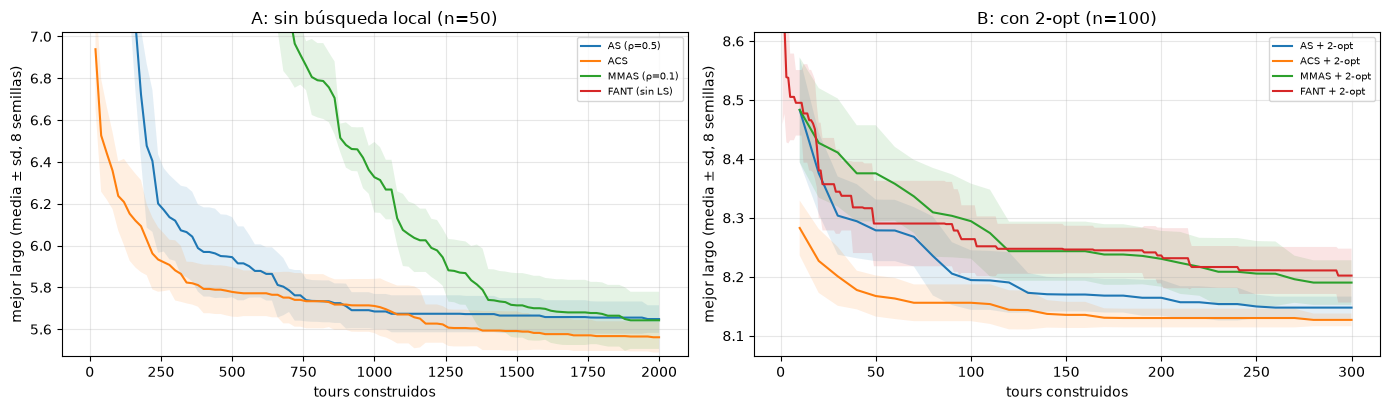

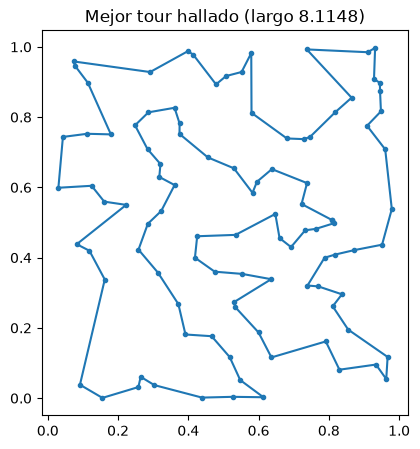

In [9]:
def curva(rs, xs):
    H = np.array([r["hist"] for r in rs]); return H.mean(0), H.std(0, ddof=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a_, res, mm, titulo, ref in ((ax[0], resA, M_ANTS, "A: sin búsqueda local (n=50)", ref_A), (ax[1], resB, M_B, "B: con 2-opt (n=100)", ref_B)):
    for k, rs in res.items():
        m, s = curva(rs, None)
        x = (np.arange(len(m)) + 1) * (mm if "FANT" not in k else 1)
        a_.plot(x, m, label=k); a_.fill_between(x, m - s, m + s, alpha=0.12)
    a_.set_xlabel("tours construidos"); a_.set_ylabel("mejor largo (media ± sd, 8 semillas)"); a_.set_title(titulo); a_.legend(fontsize=7)
    a_.set_ylim(ref - 0.05, ref + (1.5 if res is resA else 0.5))
plt.tight_layout(); plt.show()

mejor_r = min((r for rs in resB.values() for r in rs), key=lambda r: r["mejor"])
fig, ax = plt.subplots(figsize=(5, 5)); tt = mejor_r["tour"][np.r_[0:100, 0]]
ax.plot(P100[tt, 0], P100[tt, 1], "o-", ms=3); ax.set_aspect("equal"); ax.grid(False)
ax.set_title(f"Mejor tour hallado (largo {mejor_r['mejor']:.4f})"); plt.show()

**Lectura (según las tablas de arriba, semillas fijas).** Compara medias y desviaciones, no solo mínimos.
- *Escenario A (sin búsqueda local):* ACS obtiene la menor brecha media; AS y MMAS quedan cerca entre sí y FANT queda **muy por detrás**,
  algo esperable: FANT solo usa feromona (sin heurística $\eta$) y sin búsqueda local no tiene de dónde aprender en 2000 tours.
- *Escenario B (con 2-opt, $n=100$):* todas las brechas son pequeñas (la tabla las muestra): la búsqueda local hace la mayor parte de la
  mejora y las diferencias entre algoritmos se comprimen; incluso FANT, con una sola hormiga, queda a poca distancia gracias a la LS.
- Los hiperparámetros no se ajustaron por algoritmo (ver [notebook 15](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)): el
  barrido de $\rho$ de la sección siguiente muestra que, p. ej., MMAS es muy sensible a $\rho$ con este presupuesto de iteraciones.

## 11. Efecto de $\alpha$, $\beta$ y $\rho$

Barremos los tres parámetros con **AS** (sin LS, 20 hormigas, 100 iteraciones, 5 semillas por celda) y repetimos el barrido de $\rho$
para **MMAS**. Se reporta el mejor largo final medio.

[barrido α×β: 16.4s]


[barrido ρ: 5.5s]


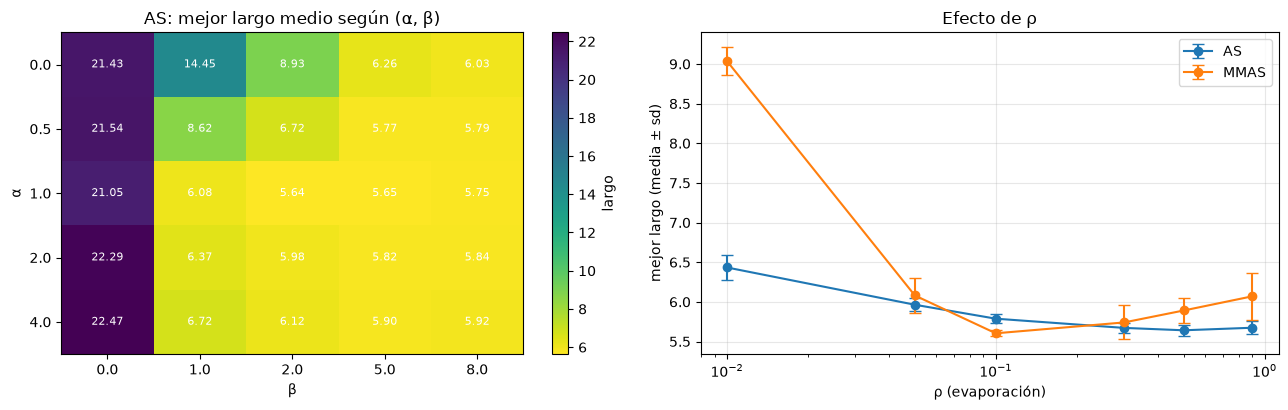

Media por β (promedio sobre α): {0.0: 21.76, 1.0: 8.45, 2.0: 6.68, 5.0: 5.88, 8.0: 5.87}
Media por α (promedio sobre β): {0.0: 11.42, 0.5: 9.69, 1.0: 8.83, 2.0: 9.26, 4.0: 9.43}
Mejor celda (α, β) de AS: α=1.0, β=2.0 → 5.6415; peor: 22.4711
ρ     | AS (media ± sd)    | MMAS (media ± sd)
0.01  | 6.4337 ± 0.1539   | 9.0366 ± 0.1783
0.05  | 5.9636 ± 0.0840   | 6.0802 ± 0.2147
0.1   | 5.7878 ± 0.0597   | 5.6035 ± 0.0389
0.3   | 5.6716 ± 0.0604   | 5.7404 ± 0.2142
0.5   | 5.6415 ± 0.0667   | 5.8911 ± 0.1620
0.9   | 5.6736 ± 0.0839   | 6.0699 ± 0.2985


In [10]:
SEM_S = list(range(5))
def media_aco(var, **kw):
    rs = [aco(D, var, 100, 20, np.random.default_rng(900 + s), **kw)["mejor"] for s in SEM_S]
    return np.mean(rs), np.std(rs, ddof=1)

alfas = [0.0, 0.5, 1.0, 2.0, 4.0]; betas = [0.0, 1.0, 2.0, 5.0, 8.0]
t0 = time.time()
G = np.zeros((len(alfas), len(betas)))
for i, a in enumerate(alfas):
    for j, b in enumerate(betas):
        G[i, j] = media_aco("as", alpha=a, beta=b, rho=0.5)[0]
print(f"[barrido α×β: {time.time()-t0:.1f}s]")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
im = ax[0].imshow(G, cmap="viridis_r", aspect="auto")
ax[0].set_xticks(range(len(betas))); ax[0].set_xticklabels(betas); ax[0].set_yticks(range(len(alfas))); ax[0].set_yticklabels(alfas)
ax[0].set_xlabel("β"); ax[0].set_ylabel("α"); ax[0].set_title("AS: mejor largo medio según (α, β)"); ax[0].grid(False)
for i in range(len(alfas)):
    for j in range(len(betas)):
        ax[0].text(j, i, f"{G[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(im, ax=ax[0], label="largo")

rhos = [0.01, 0.05, 0.1, 0.3, 0.5, 0.9]
t0 = time.time()
rr_as = [media_aco("as", alpha=1, beta=2, rho=r) for r in rhos]
rr_mm = [media_aco("mmas", alpha=1, beta=2, rho=r) for r in rhos]
print(f"[barrido ρ: {time.time()-t0:.1f}s]")
for lab, rr_ in (("AS", rr_as), ("MMAS", rr_mm)):
    ax[1].errorbar(rhos, [x[0] for x in rr_], yerr=[x[1] for x in rr_], fmt="o-", capsize=4, label=lab)
ax[1].set_xscale("log"); ax[1].set_xlabel("ρ (evaporación)"); ax[1].set_ylabel("mejor largo (media ± sd)"); ax[1].set_title("Efecto de ρ"); ax[1].legend()
plt.tight_layout(); plt.show()

print("Media por β (promedio sobre α):", {b: round(float(G[:, j].mean()), 2) for j, b in enumerate(betas)})
print("Media por α (promedio sobre β):", {a: round(float(G[i].mean()), 2) for i, a in enumerate(alfas)})
print(f"Mejor celda (α, β) de AS: α={alfas[np.unravel_index(G.argmin(), G.shape)[0]]}, β={betas[np.unravel_index(G.argmin(), G.shape)[1]]} → {G.min():.4f}; peor: {G.max():.4f}")
print("ρ     | AS (media ± sd)    | MMAS (media ± sd)")
for r, (a_, s_), (b_, t_) in zip(rhos, rr_as, rr_mm):
    print(f"{r:<5} | {a_:.4f} ± {s_:.4f}   | {b_:.4f} ± {t_:.4f}")

**Qué esperar y cómo verificarlo con las salidas.**
- **$\beta$:** sin información heurística ($\beta=0$) la búsqueda depende de que la feromona acumule señal, lo que es lento con pocas
  iteraciones: la fila $\beta=0$ de la matriz es la peor. Un $\beta$ moderado a alto es el que más ayuda en este presupuesto.
- **$\alpha$:** con $\alpha=0$ no hay aprendizaje (se reduce a vecino más cercano aleatorizado). Un $\alpha$ muy alto **sobre-refuerza**
  la feromona y conduce a convergencia prematura. Compara las columnas de la matriz.
- **$\rho$:** evaporación baja = memoria larga (exploración más prolongada, convergencia lenta); evaporación alta = memoria corta
  (convergencia rápida pero con riesgo de estancarse). El valor adecuado depende del presupuesto de iteraciones y del algoritmo: AS y MMAS
  no tienen el mismo óptimo, como muestra el gráfico de $\rho$.

## 12. Visualización de la matriz de feromona y factor de ramificación

La matriz $\tau$ es la **memoria** del sistema. La reordenamos según el mejor tour final: si la feromona se concentra en las aristas
del mejor tour, aparecerá una **banda diagonal** (aristas de ciudades consecutivas en el tour). A medida que la colonia converge, la
feromona se concentra y el **factor de ramificación**
$\lambda_{0.05}$ (nº medio de aristas por ciudad con $\tau_{ij}>\tau^i_{\min}+0.05(\tau^i_{\max}-\tau^i_{\min})$) tiende a decrecer hacia valores cercanos a 2 (cada nodo conserva solo sus dos aristas del tour) cuando la colonia converge del todo.

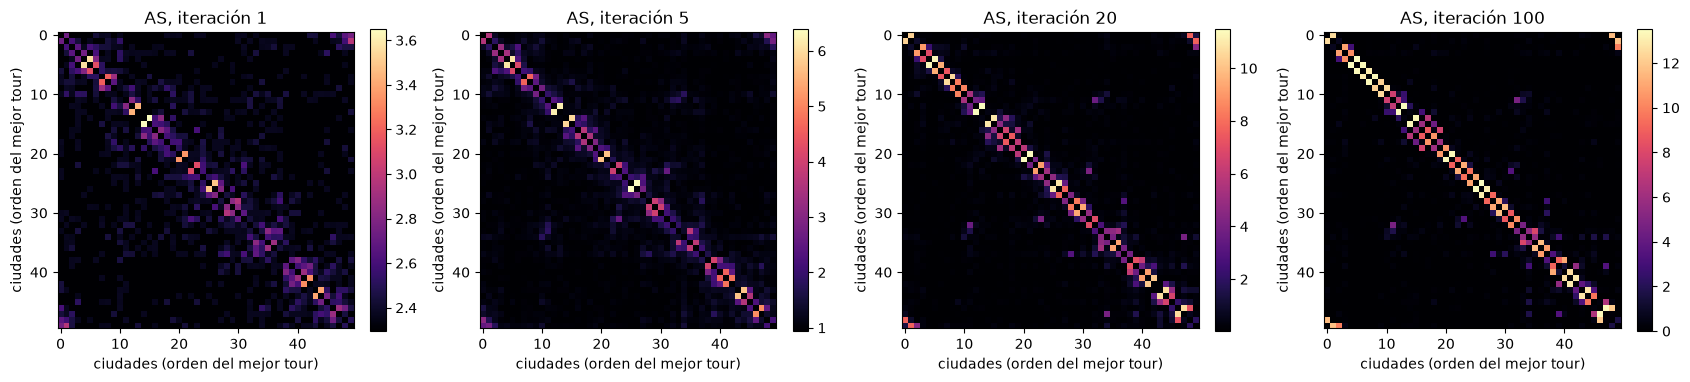

Fracción de la feromona total contenida en las aristas del mejor tour: {1: 0.048, 5: 0.11, 20: 0.525, 100: 0.661}


In [11]:
SN = (0, 4, 19, 99)
r_vis = aco(D, "as", 100, 20, np.random.default_rng(5), alpha=1, beta=2, rho=0.2, snaps=SN)
orden = r_vis["tour"]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
for a_, it in zip(ax, SN):
    M = r_vis["snaps"][it][np.ix_(orden, orden)]
    im = a_.imshow(M, cmap="magma"); a_.set_title(f"AS, iteración {it + 1}"); a_.grid(False)
    a_.set_xlabel("ciudades (orden del mejor tour)"); a_.set_ylabel("ciudades (orden del mejor tour)")
    plt.colorbar(im, ax=a_, fraction=0.046)
plt.tight_layout(); plt.show()

# Fracción de la feromona total que cae sobre las aristas del mejor tour
def frac_en_tour(tau, tour):
    # Feromona sobre las aristas del tour / feromona total sobre las aristas (fuera de la diagonal).
    a = tour; b = np.roll(tour, -1)
    return tau[a, b].sum() / ((tau.sum() - np.trace(tau)) / 2)
print("Fracción de la feromona total contenida en las aristas del mejor tour:",
      {it + 1: round(float(frac_en_tour(r_vis['snaps'][it], orden)), 3) for it in SN})

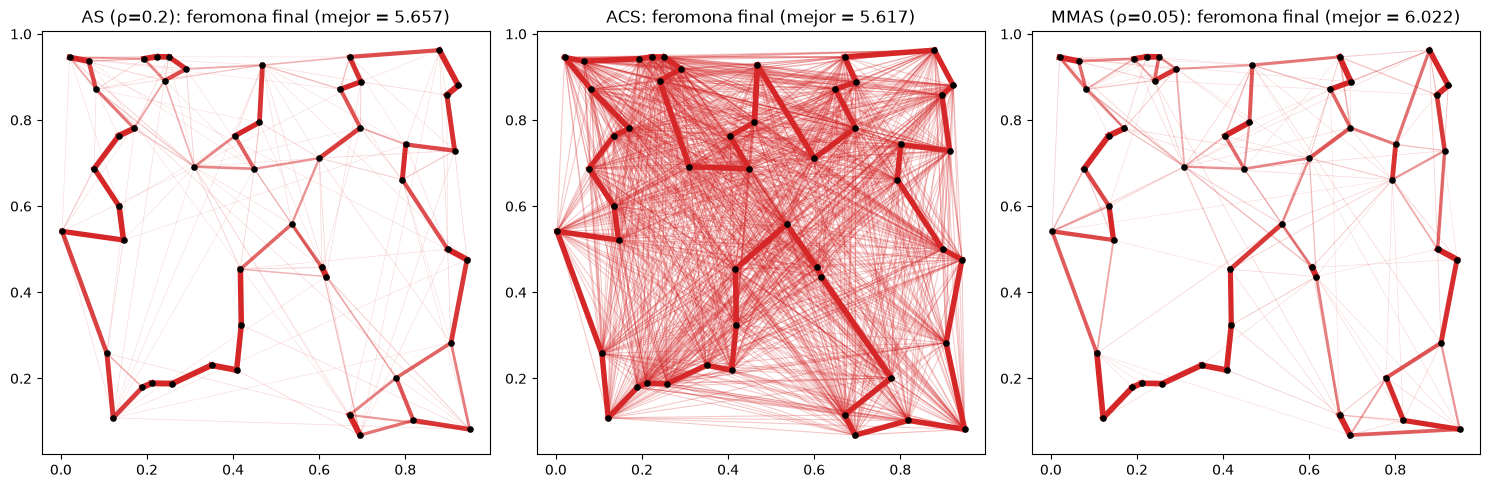

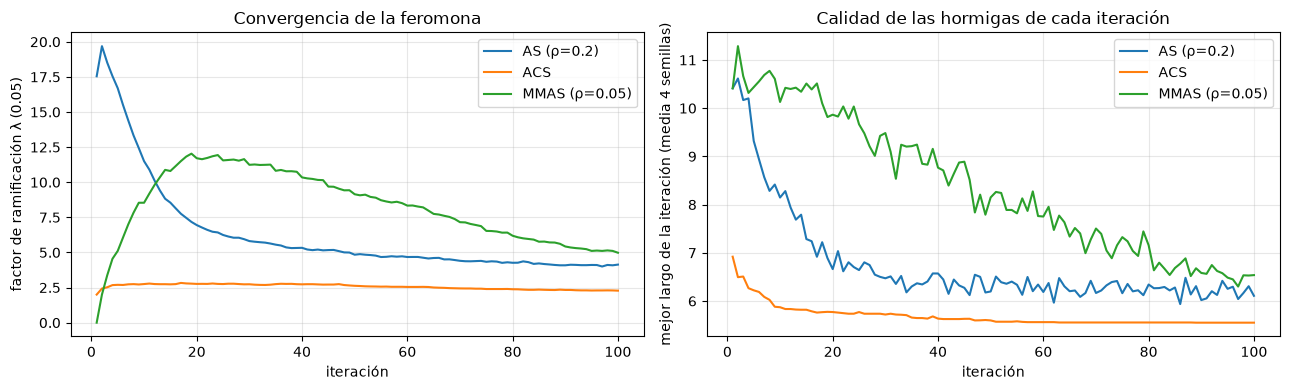

In [12]:
# Feromona sobre el plano: grosor y opacidad de cada arista proporcional a tau (AS, ACS, MMAS al final)
runs_v = {nm: aco(D, v, 100, 20, np.random.default_rng(5), rho=r_) for nm, v, r_ in
          (("AS (ρ=0.2)", "as", 0.2), ("ACS", "acs", 0.1), ("MMAS (ρ=0.05)", "mmas", 0.05))}
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a_, (nm, r_) in zip(ax, runs_v.items()):
    tau = r_["tau"]; M = tau.copy(); np.fill_diagonal(M, 0); M = M / M.max()
    ii, jj = np.where(np.triu(M, 1) > 0.02)
    for i, j in zip(ii, jj):
        a_.plot(P[[i, j], 0], P[[i, j], 1], "-", color="C3", lw=0.3 + 4 * M[i, j], alpha=min(1, 0.15 + M[i, j]))
    a_.scatter(P[:, 0], P[:, 1], s=14, c="k", zorder=3); a_.set_aspect("equal"); a_.grid(False)
    a_.set_title(f"{nm}: feromona final (mejor = {r_['mejor']:.3f})")
plt.tight_layout(); plt.show()

# Factor de ramificación a lo largo de las iteraciones (media de 4 semillas)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for var, r_, nm in (("as", 0.2, "AS (ρ=0.2)"), ("acs", 0.1, "ACS"), ("mmas", 0.05, "MMAS (ρ=0.05)")):
    ram = np.mean([aco(D, var, 100, 20, np.random.default_rng(50 + s), rho=r_)["ramif"] for s in range(4)], 0)
    ax[0].plot(np.arange(1, 101), ram, label=nm)
ax[0].set_xlabel("iteración"); ax[0].set_ylabel("factor de ramificación λ (0.05)"); ax[0].set_title("Convergencia de la feromona"); ax[0].legend()
for var, r_, nm in (("as", 0.2, "AS (ρ=0.2)"), ("acs", 0.1, "ACS"), ("mmas", 0.05, "MMAS (ρ=0.05)")):
    hi = np.mean([aco(D, var, 100, 20, np.random.default_rng(50 + s), rho=r_)["hist_it"] for s in range(4)], 0)
    ax[1].plot(np.arange(1, 101), hi, label=nm)
ax[1].set_xlabel("iteración"); ax[1].set_ylabel("mejor largo de la iteración (media 4 semillas)"); ax[1].set_title("Calidad de las hormigas de cada iteración"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura (de las curvas de arriba).** Con feromona perfectamente uniforme el factor de ramificación vale 0 *por definición* (ninguna
arista supera el umbral), de modo que solo es informativo después de las primeras actualizaciones.
- **AS** sube en las primeras iteraciones (los primeros depósitos diferencian aristas) y luego **decae** de forma sostenida: la colonia
  se concentra; el valor al que se acerca al final indica cuántas alternativas por ciudad siguen vivas.
- **MMAS** (con $\rho=0.05$, evaporación lenta) parte de $\tau_{\max}$ uniforme y la diferenciación es **más lenta y más gradual**; sus límites
  $[\tau_{\min},\tau_{\max}]$ impiden que el factor colapse. Por eso la calidad de sus hormigas mejora más despacio (panel derecho), un
  costo de su exploración extensa con 100 iteraciones.
- **ACS** se mantiene casi constante en un valor bajo desde el inicio: la actualización global solo refuerza el mejor tour global y la
  explotación $q_0=0.9$ es muy intensificadora; la actualización local es lo que evita que todas las hormigas sigan idénticas.
  Sus hormigas son de buena calidad casi desde el principio.

Un factor de ramificación que cae a valores cercanos a 2 mientras el mejor largo sigue lejos de la referencia indica **estancamiento
prematuro**: es la señal para reducir $\alpha$, aumentar la evaporación o recurrir a los reinicios de MMAS/FANT.

## Ventajas y limitaciones

| Aspecto | Ventajas | Limitaciones |
|---|---|---|
| Memoria | feromona = memoria distribuida y adaptativa; combina información global (feromona) y local ($\eta$) | memoria $O(n^2)$; la información se mezcla (no se puede distinguir de qué iteración viene cada rastro) |
| Paralelismo | las hormigas de una iteración son independientes (aquí, vectorizadas) | la actualización local de ACS introduce dependencia secuencial |
| Parámetros | AS tiene $\alpha,\beta,\rho,m,Q$; MMAS y ACS añaden límites y $q_0,\xi$; FANT casi no tiene | sensibles a la instancia; hay que calibrar (notebook 15) |
| Calidad | con búsqueda local, ACS y MMAS son competitivos en TSP y QAP | sin búsqueda local, rinden poco frente a métodos de trayectoria bien diseñados; AS puro estanca fácilmente |
| Aplicabilidad | natural en problemas de **construcción** (TSP, ruteo, asignación, secuenciación) | poco natural en espacios continuos (existen extensiones) |

## Resumen
- ACO = **construcción probabilística** guiada por feromona $\tau$ y heurística $\eta$; la feromona se actualiza con evaporación y depósito.
- La evaporación acota la feromona: con depósito constante $\Delta$, $\tau^*=\Delta/\rho$ (base de $\tau_{\max}$ en MMAS).
- **AS** depositan todas las hormigas; **ACS** intensifica (regla $q_0$, solo la mejor global) y diversifica (actualización local); **MMAS** deposita
  una sola hormiga y limita $\tau\in[\tau_{\min},\tau_{\max}]$ con reinicio; **FANT** usa una hormiga, sin evaporación ni $\eta$, y reinicia/ajusta la traza.
- $\alpha$ y $\beta$ equilibran memoria colectiva y voracidad; $\rho$ define cuánto se recuerda. El factor de ramificación diagnostica el estancamiento.
- La comparación honesta usa presupuesto igual (tours construidos), varias semillas y reporta media $\pm$ desviación, con y sin búsqueda local.

## Ejercicios propuestos
1. Agrega una **lista de candidatos** (solo los 15 vecinos más cercanos) a la construcción y mide el cambio de tiempo y calidad.
2. Implementa el **ranking de hormigas** (*rank-based AS*): solo depositan las $w$ mejores con peso proporcional al rango.
3. Adapta ACO al **QAP**: la feromona $\tau_{i\ell}$ asocia unidad $i$ con ubicación $\ell$; compara con el *Robust Tabu Search* del [notebook 06](06-busqueda-tabu.ipynb).
4. Modifica FANT para que el incremento de la traza dependa de la calidad ($\propto 1/L$) y compara.
5. Estudia cómo escala el factor de ramificación final con $\rho$ y $n$.
6. Combina ACO con Path Relinking ([notebook 07](07-grasp-path-relinking.ipynb)) para generar soluciones élite.

## Referencias
- Dorigo, M., Maniezzo, V. & Colorni, A. (1996). *Ant System: Optimization by a colony of cooperating agents*. IEEE Transactions on Systems, Man, and Cybernetics – Part B, 26(1).
- Dorigo, M. & Gambardella, L. M. (1997). *Ant Colony System: A cooperative learning approach to the traveling salesman problem*. IEEE Transactions on Evolutionary Computation, 1(1).
- Stützle, T. & Hoos, H. H. (2000). *MAX–MIN Ant System*. Future Generation Computer Systems, 16(8).
- Taillard, É. D. (1998). *FANT: Fast Ant System*. Technical report IDSIA-46-98.
- Dorigo, M. & Stützle, T. (2004). *Ant Colony Optimization*. MIT Press.
- Gambardella, L. M. & Dorigo, M. (1995). *Ant-Q: A reinforcement learning approach to the traveling salesman problem*. ICML.